# COS802 Project — Housing Price Prediction
## Notebook 01: Data Audit and Exploratory Data Analysis

**Project:** Housing Price Prediction with Regression and Feature Importance Analysis

### Purpose
Audit the Ames Housing dataset before preprocessing, feature engineering, and modelling.

Objectives: verify dimensions/schema; inspect data types and duplicates; analyse missingness and `SalePrice`; explore key predictors; audit engineered-feature sources; and create a reproducible 80/20 development/test split.

**No predictive models are trained in this notebook.**

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path
import platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version
from sklearn.model_selection import train_test_split

SEED = 16153970
np.random.seed(SEED)

print(f"Python: {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {sklearn_version}")
print(f"Random seed: {SEED}")

Python: 3.13.15
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Random seed: 16153970


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
SPLITS_DIR = PROJECT_DIR / "data" / "splits"
FIGURES_DIR = PROJECT_DIR / "figures"
DATA_FILE = RAW_DIR / "AmesHousing.txt"

for d in [PROCESSED_DIR, SPLITS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_FILE)
print("Dataset exists:", DATA_FILE.exists())

Dataset: /content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT/data/raw/AmesHousing.txt
Dataset exists: True


In [4]:
df = pd.read_csv(DATA_FILE, sep="\t")
TARGET = "SalePrice"
IDENTIFIERS = ["Order", "PID"]
print(f"Rows: {df.shape[0]:,}; Columns: {df.shape[1]:,}")
display(df.head())
print("Target present:", TARGET in df.columns)

Rows: 2,930; Columns: 82


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


Target present: True


In [5]:
dtype_summary = df.dtypes.astype(str).value_counts().rename_axis("dtype").reset_index(name="count")
display(dtype_summary)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print(f"Numeric: {len(numeric_cols)} | Categorical: {len(categorical_cols)} | Total: {df.shape[1]}")

,dtype,count
0,object,43
1,int64,28
2,float64,11


Numeric: 39 | Categorical: 43 | Total: 82


In [6]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
for c in IDENTIFIERS:
    print(f"{c}: {df[c].nunique(dropna=False):,} unique values / {len(df):,} rows")

Exact duplicate rows: 0
Order: 2,930 unique values / 2,930 rows
PID: 2,930 unique values / 2,930 rows


In [7]:
missing_summary = df.isna().sum().to_frame("Missing")
missing_summary["Percent"] = missing_summary["Missing"] / len(df) * 100
missing_summary = missing_summary[missing_summary["Missing"] > 0].sort_values("Percent", ascending=False)
print(f"Columns containing missing values: {len(missing_summary)}")
display(missing_summary)
missing_summary.to_csv(PROCESSED_DIR / "missing_value_summary.csv")

Columns containing missing values: 27


,Missing,Percent
Pool QC,2917,99.556314
Misc Feature,2824,96.382253
Alley,2732,93.242321
Fence,2358,80.477816
Mas Vnr Type,1775,60.580205
Fireplace Qu,1422,48.532423
Lot Frontage,490,16.723549
Garage Qual,159,5.426621
Garage Cond,159,5.426621
Garage Yr Blt,159,5.426621


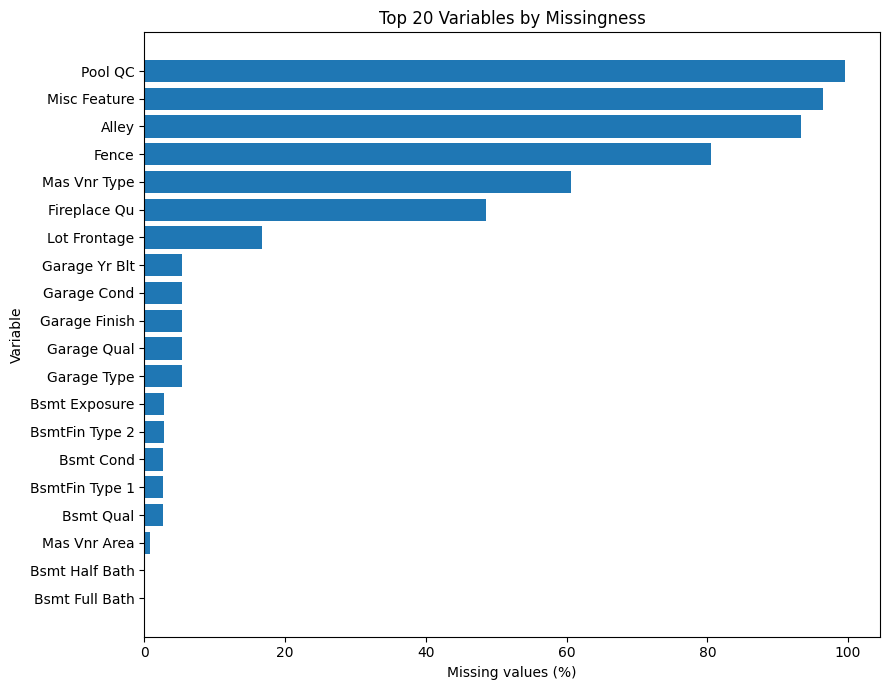

In [8]:
plot_data = missing_summary.head(20).sort_values("Percent")
plt.figure(figsize=(9,7))
plt.barh(plot_data.index, plot_data["Percent"])
plt.xlabel("Missing values (%)"); plt.ylabel("Variable")
plt.title("Top 20 Variables by Missingness"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "missingness_top20.png", dpi=300, bbox_inches="tight")
plt.show()

## Freeze the Development/Test Split Before Target-Informed EDA
The dataset is split **before any target-informed exploration**. Whole-dataset checks above are limited to schema, duplicates and missingness. From this point onward, any analysis involving `SalePrice` uses only the 2,344-row development set. The 586-row test set is locked until the final evaluation notebook.


In [9]:
all_indices = df.index.to_numpy()
dev_idx, test_idx = train_test_split(
    all_indices, test_size=0.20, random_state=SEED, shuffle=True
)
dev_df = df.loc[dev_idx].copy()
test_df = df.loc[test_idx].copy()

print(f"Total: {len(df):,}")
print(f"Development: {len(dev_idx):,}")
print(f"Locked test: {len(test_idx):,}")
print("All target-informed EDA below uses development data only.")


Total: 2,930
Development: 2,344
Locked test: 586
All target-informed EDA below uses development data only.


In [10]:
split_membership = pd.DataFrame({
 "row_index": np.concatenate([dev_idx,test_idx]),
 "split": ["development"]*len(dev_idx) + ["test"]*len(test_idx)
})
split_membership.to_csv(SPLITS_DIR / "train_test_split.csv", index=False)
display(split_membership["split"].value_counts())

,count
split,
development,2344
test,586


In [11]:
assert not set(dev_idx).intersection(test_idx)
assert len(dev_idx)+len(test_idx)==len(df)
assert set(dev_idx).union(test_idx)==set(df.index)
print("Split integrity checks passed.")

Split integrity checks passed.


In [12]:
display(dev_df[TARGET].describe())
print(f"Missing target (development): {dev_df[TARGET].isna().sum():,}")
print(f"Minimum: ${dev_df[TARGET].min():,.0f}")
print(f"Median: ${dev_df[TARGET].median():,.0f}")
print(f"Mean: ${dev_df[TARGET].mean():,.0f}")
print(f"Maximum: ${dev_df[TARGET].max():,.0f}")
print(f"Skewness: {dev_df[TARGET].skew():.3f}")


,SalePrice
count,2344.000000
mean,181054.365188
std,79816.982799
min,12789.000000
25%,129500.000000
50%,160375.000000
75%,213000.000000
max,755000.000000


Missing target (development): 0
Minimum: $12,789
Median: $160,375
Mean: $181,054
Maximum: $755,000
Skewness: 1.704


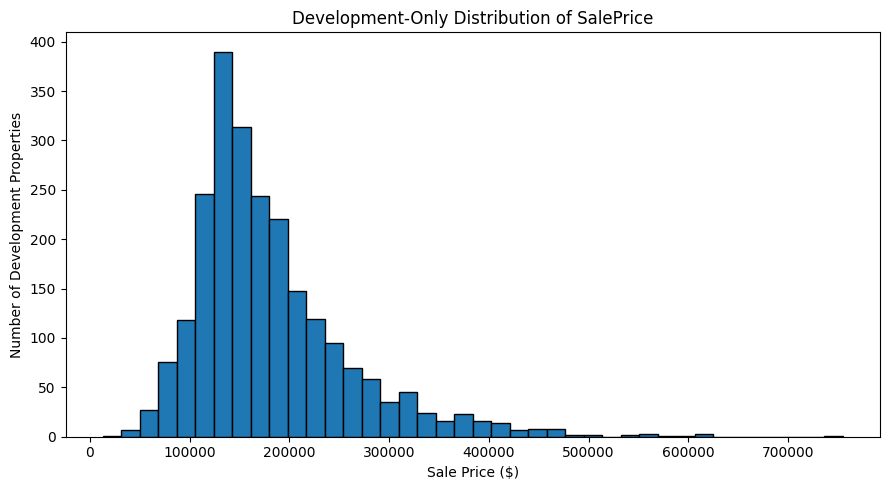

In [13]:
plt.figure(figsize=(9,5))
plt.hist(dev_df[TARGET], bins=40, edgecolor="black")
plt.xlabel("Sale Price ($)"); plt.ylabel("Number of Development Properties")
plt.title("Development-Only Distribution of SalePrice"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "saleprice_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


Development raw-target skewness: 1.704
Development log1p-target skewness: 0.076


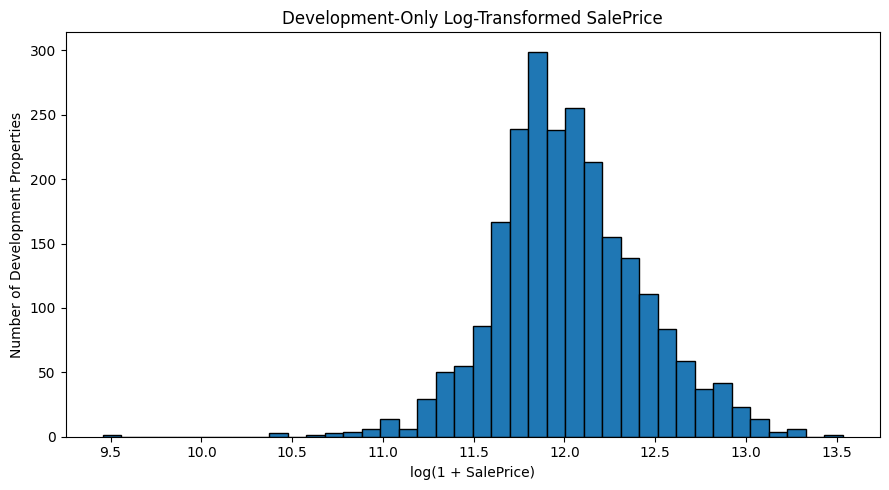

In [14]:
log_saleprice = np.log1p(dev_df[TARGET])
print(f"Development raw-target skewness: {dev_df[TARGET].skew():.3f}")
print(f"Development log1p-target skewness: {log_saleprice.skew():.3f}")
plt.figure(figsize=(9,5))
plt.hist(log_saleprice, bins=40, edgecolor="black")
plt.xlabel("log(1 + SalePrice)"); plt.ylabel("Number of Development Properties")
plt.title("Development-Only Log-Transformed SalePrice"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "saleprice_log_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


,count
Yr Sold,
2006,625
2007,694
2008,622
2009,648
2010,341


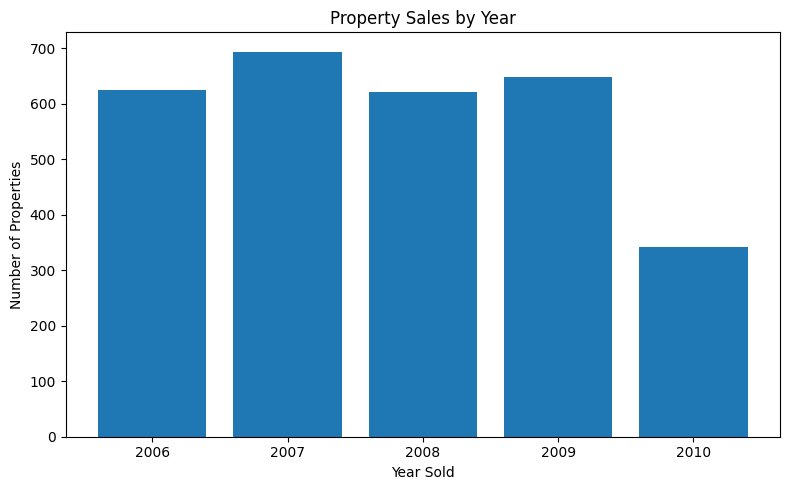

In [15]:
year_counts = df["Yr Sold"].value_counts().sort_index()
display(year_counts)
plt.figure(figsize=(8,5))
plt.bar(year_counts.index.astype(str), year_counts.values)
plt.xlabel("Year Sold"); plt.ylabel("Number of Properties")
plt.title("Property Sales by Year"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "sales_by_year.png", dpi=300, bbox_inches="tight")
plt.show()

,SalePrice
Overall Qual,0.802110
Gr Liv Area,0.706576
Garage Cars,0.644231
Garage Area,0.638357
Total Bsmt SF,0.628058
1st Flr SF,0.626580
Year Built,0.553946
Full Bath,0.548517
Year Remod/Add,0.542422
Garage Yr Blt,0.523794


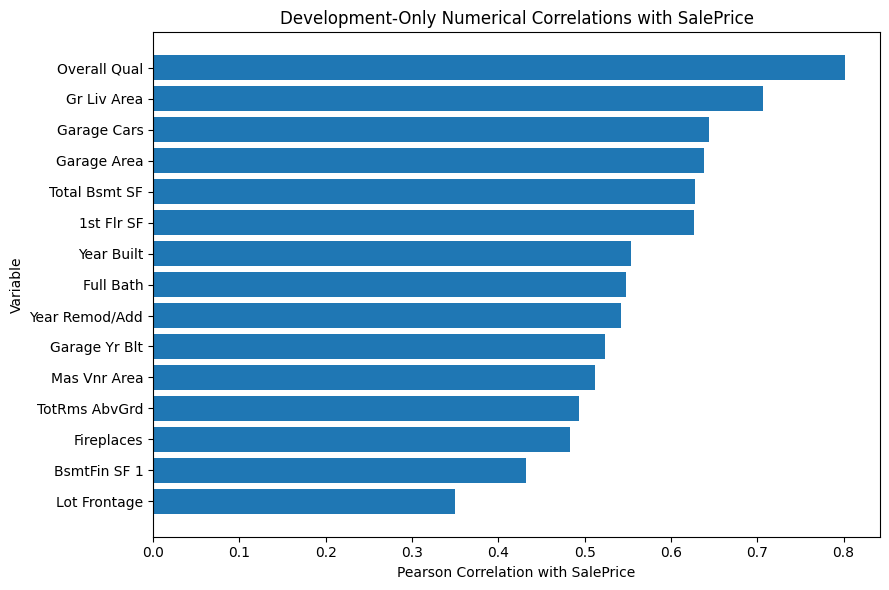

In [16]:
numeric_for_corr = [c for c in numeric_cols if c not in IDENTIFIERS]
correlations = dev_df[numeric_for_corr].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
display(correlations.head(15))
top_corr = correlations.head(15).sort_values()
plt.figure(figsize=(9,6))
plt.barh(top_corr.index, top_corr.values)
plt.xlabel("Pearson Correlation with SalePrice"); plt.ylabel("Variable")
plt.title("Development-Only Numerical Correlations with SalePrice"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_numeric_correlations.png", dpi=300, bbox_inches="tight")
plt.show()


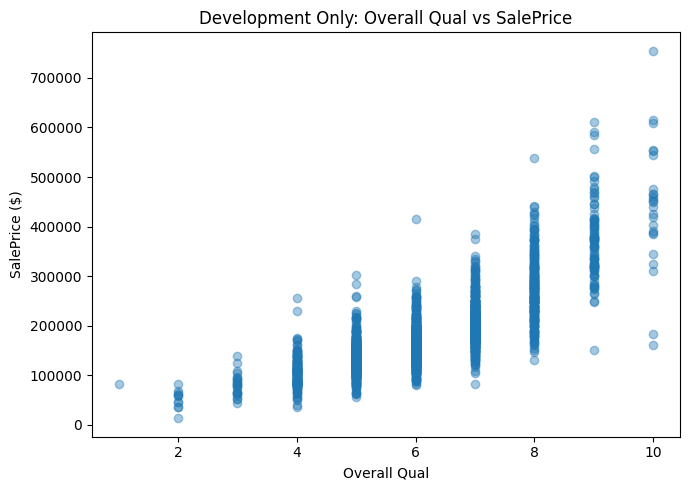

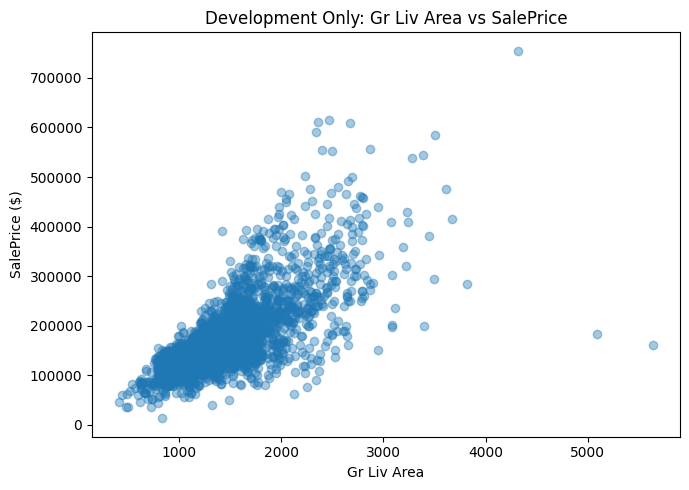

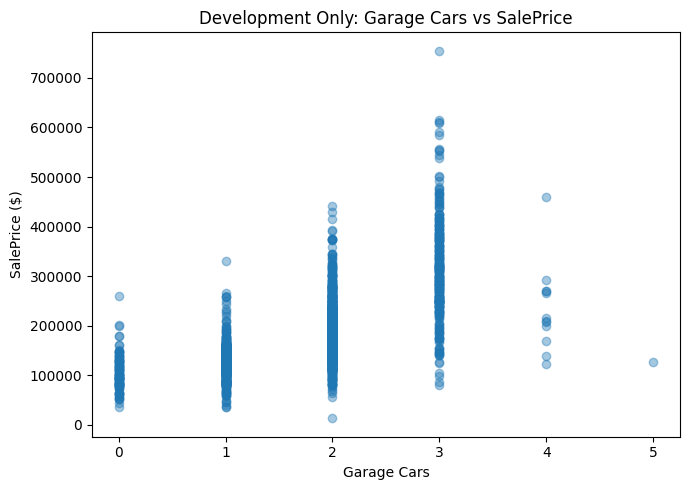

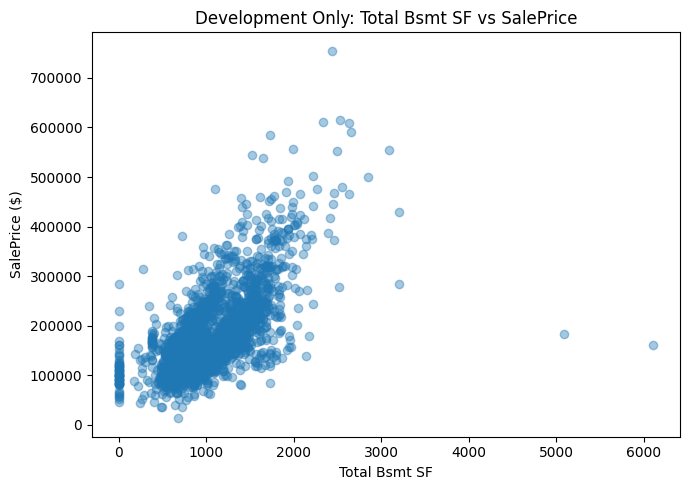

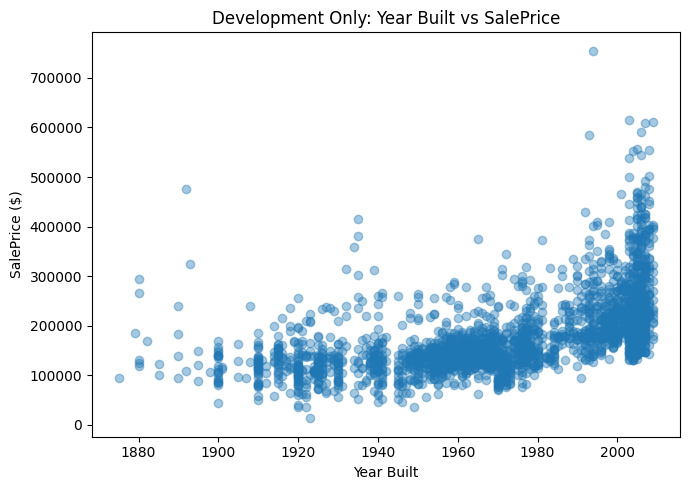

In [17]:
key_numeric = ["Overall Qual","Gr Liv Area","Garage Cars","Total Bsmt SF","Year Built"]
for feature in key_numeric:
    if feature in dev_df.columns:
        plt.figure(figsize=(7,5))
        plt.scatter(dev_df[feature], dev_df[TARGET], alpha=0.4)
        plt.xlabel(feature); plt.ylabel("SalePrice ($)")
        plt.title(f"Development Only: {feature} vs SalePrice"); plt.tight_layout()
        safe = feature.lower().replace(" ","_").replace("/","_")
        plt.savefig(FIGURES_DIR / f"{safe}_vs_saleprice.png", dpi=300, bbox_inches="tight")
        plt.show()


In [18]:
categorical_cardinality = df[categorical_cols].nunique(dropna=False).sort_values(ascending=False).to_frame("Unique_Values")
display(categorical_cardinality.head(20))

,Unique_Values
Neighborhood,28
Exterior 2nd,17
Exterior 1st,16
Sale Type,10
Condition 1,9
House Style,8
Functional,8
Roof Matl,8
Condition 2,8
MS Zoning,7


,count,median,mean
Neighborhood,,,
NridgHt,138,318780.5,322829.507246
NoRidge,54,306000.0,327512.185185
GrnHill,2,280000.0,280000.000000
StoneBr,44,276500.0,317133.113636
Timber,54,240250.0,247269.203704
Veenker,16,229800.0,237709.375000
Somerst,137,226000.0,230646.532847
Crawfor,78,206567.5,210438.282051
CollgCr,211,200000.0,201232.824645


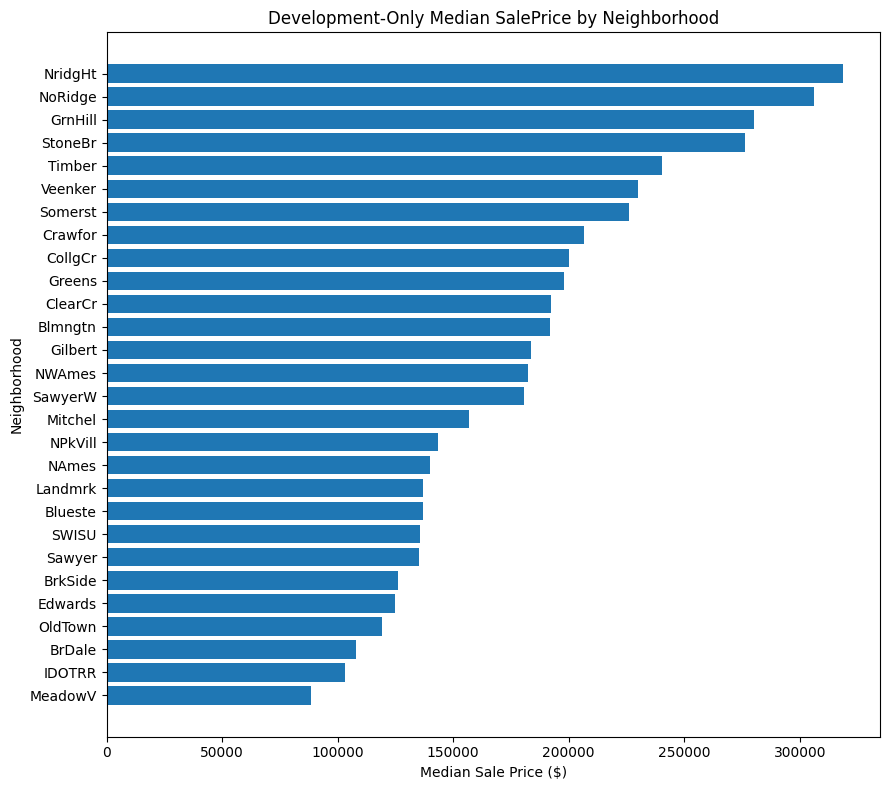

In [19]:
neighborhood_summary = dev_df.groupby("Neighborhood")[TARGET].agg(["count","median","mean"]).sort_values("median", ascending=False)
display(neighborhood_summary)
plot_data = neighborhood_summary.sort_values("median")
plt.figure(figsize=(9,8))
plt.barh(plot_data.index, plot_data["median"])
plt.xlabel("Median Sale Price ($)"); plt.ylabel("Neighborhood")
plt.title("Development-Only Median SalePrice by Neighborhood"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "median_saleprice_by_neighborhood.png", dpi=300, bbox_inches="tight")
plt.show()


In [20]:
feature_sources = {
 "HouseAge":["Yr Sold","Year Built"],
 "RemodAge":["Yr Sold","Year Remod/Add"],
 "TotalSF":["Total Bsmt SF","1st Flr SF","2nd Flr SF"],
 "TotalBathrooms":["Full Bath","Half Bath","Bsmt Full Bath","Bsmt Half Bath"],
 "TotalPorchSF":["Open Porch SF","Enclosed Porch","3Ssn Porch","Screen Porch","Wood Deck SF"],
 "AmenityIndicators":["Garage Area","Total Bsmt SF","Fireplaces","Pool Area"]
}
for name, sources in feature_sources.items():
    missing = [c for c in sources if c not in df.columns]
    print(f"{name}: {'MISSING '+str(missing) if missing else 'all source columns available'}")

HouseAge: all source columns available
RemodAge: all source columns available
TotalSF: all source columns available
TotalBathrooms: all source columns available
TotalPorchSF: all source columns available
AmenityIndicators: all source columns available


In [21]:
summary = {
 "observations":len(df), "columns":df.shape[1],
 "numeric_columns":len(numeric_cols), "categorical_columns":len(categorical_cols),
 "duplicate_rows":int(df.duplicated().sum()),
 "columns_with_missing_values":len(missing_summary),
 "target_missing":int(df[TARGET].isna().sum()),
 "saleprice_mean":float(df[TARGET].mean()),
 "saleprice_median":float(df[TARGET].median()),
 "saleprice_skewness":float(df[TARGET].skew()),
 "development_rows":len(dev_idx), "test_rows":len(test_idx), "random_seed":SEED
}
display(pd.Series(summary))

,0
observations,2.930000e+03
columns,8.200000e+01
numeric_columns,3.900000e+01
categorical_columns,4.300000e+01
duplicate_rows,0.000000e+00
columns_with_missing_values,2.700000e+01
target_missing,0.000000e+00
saleprice_mean,1.807961e+05
saleprice_median,1.600000e+05
saleprice_skewness,1.743500e+00


## Exploratory Property Segmentation — K-Means and PCA

Following the COS802 unsupervised-learning workflow, this supplementary EDA uses **development data only**. `SalePrice` is excluded when clusters are formed and is used only afterwards to profile the discovered groups. K-Means provides exploratory property segmentation, while PCA provides a two-dimensional visualisation of the high-dimensional representation.


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

dev_df = df.loc[dev_idx].copy()
X_cluster = dev_df.drop(columns=[TARGET] + IDENTIFIERS)
cn = X_cluster.select_dtypes(include=np.number).columns.tolist()
cc = X_cluster.select_dtypes(exclude=np.number).columns.tolist()

cluster_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), cn),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cc)
])
Xcp = cluster_preprocessor.fit_transform(X_cluster)
print("Development rows:", Xcp.shape[0])
print("Processed dimensions:", Xcp.shape[1])


Development rows: 2344
Processed dimensions: 300


### Elbow analysis
K-Means requires a chosen number of clusters. We inspect inertia for candidate K values; the elbow is treated as exploratory evidence rather than an automatic rule.


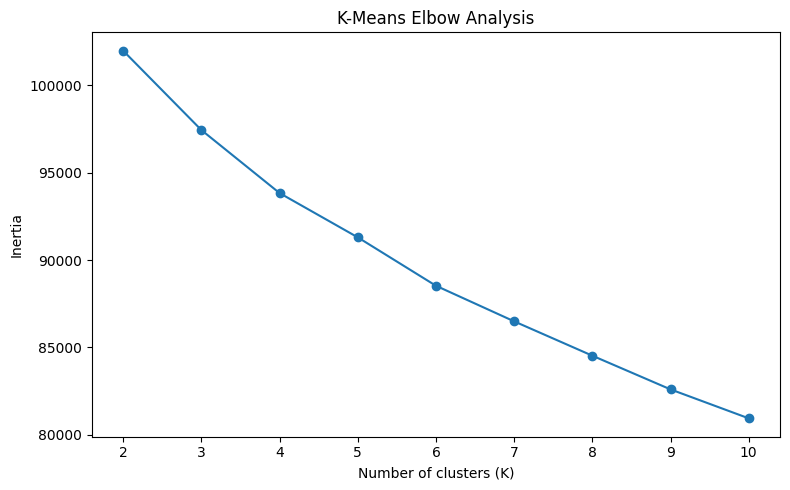

,K,Inertia
0,2,101988.288022
1,3,97447.375047
2,4,93839.450602
3,5,91305.306977
4,6,88534.030142
5,7,86496.477457
6,8,84530.179258
7,9,82601.719371
8,10,80944.367656


In [23]:
ks = list(range(2, 11))
inertias = []
for k in ks:
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    model.fit(Xcp)
    inertias.append(model.inertia_)

plt.figure(figsize=(8,5))
plt.plot(ks, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Analysis")
plt.xticks(ks)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "kmeans_elbow.png", dpi=300, bbox_inches="tight")
plt.show()
display(pd.DataFrame({"K":ks, "Inertia":inertias}))


### Fit K-Means
After inspecting the elbow plot, change `SELECTED_K` if the evidence supports another value. The initial value below is only a starting point.


In [27]:
SELECTED_K = 3
kmeans = KMeans(n_clusters=SELECTED_K, random_state=SEED, n_init=10)
labels = kmeans.fit_predict(Xcp)
dev_df["Cluster"] = labels
display(dev_df["Cluster"].value_counts().sort_index().rename("Properties").to_frame())


,Properties
Cluster,
0,540
1,550
2,1254


### PCA visualisation
PCA is used only to visualise the high-dimensional property representation in two dimensions; it is not part of the regression pipeline.


Explained variance ratio: [0.17153312 0.07379047]
Total 2D explained variance: 0.2453235822120497


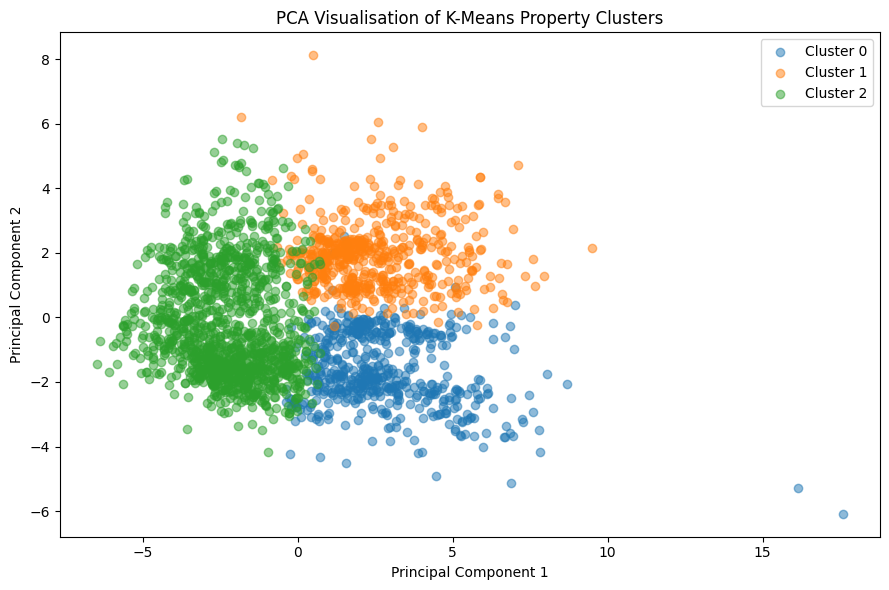

In [28]:
X_dense = Xcp.toarray() if hasattr(Xcp, "toarray") else Xcp
pca = PCA(n_components=2, random_state=SEED)
Xp = pca.fit_transform(X_dense)

pca_df = pd.DataFrame({"PC1":Xp[:,0], "PC2":Xp[:,1], "Cluster":labels})
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total 2D explained variance:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(9,6))
for c in sorted(pca_df.Cluster.unique()):
    s=pca_df[pca_df.Cluster==c]
    plt.scatter(s.PC1, s.PC2, alpha=.5, label=f"Cluster {c}")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualisation of K-Means Property Clusters")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "kmeans_pca_clusters.png", dpi=300, bbox_inches="tight")
plt.show()


### Cluster profiling
The clusters are now described using understandable property characteristics. `SalePrice` appears only at this interpretation stage and did not determine cluster membership.


,Overall Qual,Gr Liv Area,Year Built,Total Bsmt SF,Garage Cars,SalePrice,Number of Properties
Cluster,,,,,,,
0,7.0,1555.0,2004.0,1494.0,2.0,221400.0,540
1,7.0,1885.0,1999.0,925.0,2.0,211000.0,550
2,5.0,1175.0,1957.0,892.0,1.0,131625.0,1254


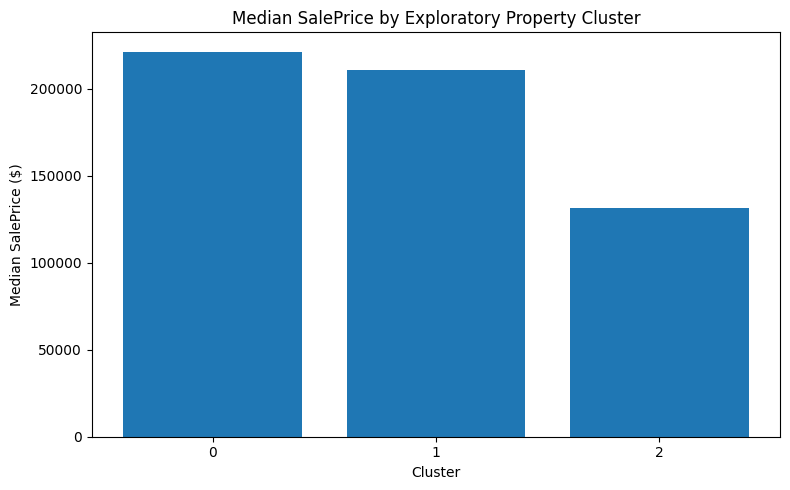

In [29]:
profile_cols = ["Overall Qual","Gr Liv Area","Year Built","Total Bsmt SF","Garage Cars",TARGET]
profile_cols = [c for c in profile_cols if c in dev_df.columns]
profile = dev_df.groupby("Cluster")[profile_cols].median(numeric_only=True).round(1)
profile["Number of Properties"] = dev_df.groupby("Cluster").size()
display(profile)
profile.to_csv(PROCESSED_DIR / "cluster_profile.csv")

price_cluster = dev_df.groupby("Cluster")[TARGET].median().sort_index()
plt.figure(figsize=(8,5))
plt.bar(price_cluster.index.astype(str), price_cluster.values)
plt.xlabel("Cluster")
plt.ylabel("Median SalePrice ($)")
plt.title("Median SalePrice by Exploratory Property Cluster")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "median_saleprice_by_cluster.png", dpi=300, bbox_inches="tight")
plt.show()


### Interpretation
Cluster labels must be derived from the observed profile rather than assigned in advance. This analysis is supplementary EDA; the project's primary task remains supervised regression for housing-price prediction.


## EDA Conclusions
- `Order` and `PID` are identifiers and will be excluded from modelling.
- The development/test split is frozen **before target-informed EDA**.
- All target distributions, target correlations, target scatterplots and neighborhood price summaries use development data only.
- Missing values require feature-specific treatment because some represent absent property components.
- `SalePrice` is positively skewed; raw-versus-log target behaviour will be evaluated using development cross-validation.
- Candidate engineered features can be constructed deterministically from existing property attributes.
- K-Means/PCA remains supplementary development-only EDA and is not used to select the final regression model.
- The held-out test set will not guide preprocessing, feature selection or hyperparameter tuning.

Notebook 02 constructs the reproducible preprocessing and feature-engineering pipeline.
